In [1]:
import sys, subprocess, importlib
for pkg in ["catboost", "optuna", "shap"]:
    try: importlib.import_module(pkg)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])
import os, time, glob, zipfile, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import optuna
from catboost import CatBoostClassifier, Pool
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, brier_score_loss, roc_curve, precision_recall_curve)
warnings.filterwarnings("ignore"); optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42; np.random.seed(SEED); OUT = "outputs_improved"; os.makedirs(OUT, exist_ok=True)

In [2]:
try:
    from google.colab import files
    files.upload()                      # choose bank_cleaned_csv__1_.zip or bank_cleaned.csv
except ImportError: pass
for f in glob.glob("*.zip"): zipfile.ZipFile(f).extractall(".")
CSV = glob.glob("**/bank_cleaned.csv", recursive=True)[0]
df = pd.read_csv(CSV, index_col=0).reset_index(drop=True)   # row order = original order (assumed chronological)
y_all = df["response_binary"].values
print(df.shape, "| positive rate: %.2f%%" % (100*y_all.mean()))

Saving bank_cleaned.csv (1) (1).zip to bank_cleaned.csv (1) (1).zip
(40841, 17) | positive rate: 11.36%


In [10]:
n = len(df); a, b = int(.6*n), int(.8*n)
seg = np.array(["train(first 60%)"]*a + ["val(next 20%)"]*(b-a) + ["test(last 20%)"]*(n-b))
print(pd.Series(y_all).groupby(seg).mean().round(3).rename("positive rate"))
tab = pd.crosstab(df["month"], seg, values=y_all, aggfunc="mean").round(2); tab["n_test"] = pd.crosstab(df["month"], seg).get("test(last 20%)", 0)
display(tab)

test(last 20%)      0.297
train(first 60%)    0.049
val(next 20%)       0.123
Name: positive rate, dtype: float64


col_0,test(last 20%),train(first 60%),val(next 20%),n_test
month,,,,
apr,0.61,NaN,0.17,164
aug,0.39,0.06,NaN,859
dec,0.49,NaN,0.08,160
feb,0.54,NaN,0.12,290
jan,0.48,NaN,0.03,180
jul,0.45,0.06,NaN,417
jun,0.41,0.05,NaN,736
mar,0.58,NaN,0.51,171
may,0.12,0.03,0.10,3883


In [11]:
def get_splits(mode):
    idx = np.arange(len(df))
    if mode == "random":
        tr, tmp = train_test_split(idx, test_size=0.4, stratify=y_all, random_state=SEED)
        va, te  = train_test_split(tmp, test_size=0.5, stratify=y_all[tmp], random_state=SEED)
    else:                                   # chronological by row order
        tr, va, te = idx[:a], idx[a:b], idx[b:]
    return tr, va, te

def get_features(exp):
    X = df.drop(columns=["response", "response_binary"] + ([] if exp == "A" else ["duration"])).copy()
    cats = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    for c in cats: X[c] = X[c].astype(str).astype(object)
    return X, cats, [c for c in X.columns if c not in cats]

def make_prep(cats, nums):
    return ColumnTransformer([("num", StandardScaler(), nums),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats)])

In [12]:
_trap = getattr(np, "trapezoid", None) or np.trapz
def alift(y, s):
    o = np.argsort(-s, kind="mergesort"); cum = np.concatenate([[0], np.cumsum(y[o]) / y.sum()])
    return _trap(cum, np.linspace(0, 1, len(y) + 1))
def capture(y, s, frac):                       # % of all responders found in the top `frac` of customers
    o = np.argsort(-s, kind="mergesort"); k = int(round(frac * len(y))); return 100 * y[o][:k].sum() / y.sum()
def best_f1_threshold(y, p):                   # chosen on VALIDATION only
    pr, rc, th = precision_recall_curve(y, p); f1 = 2*pr*rc/np.maximum(pr+rc, 1e-12)
    return th[np.argmax(f1[:-1])]
def evaluate(name, y, p, thr, t_train):
    pred = (p >= thr).astype(int)
    return {"Model": name, "ROC-AUC": roc_auc_score(y, p), "PR-AUC (avg precision)": average_precision_score(y, p),
            "Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred), "Threshold": thr, "Brier": brier_score_loss(y, p),
            "ALIFT": alift(y, p), "Top10% captured": capture(y, p, .1), "Top20% captured": capture(y, p, .2),
            "Top50% captured": capture(y, p, .5), "Lift@10%": capture(y, p, .1) / 10, "Train time (s)": t_train}

In [13]:
class NNEns(BaseEstimator, ClassifierMixin):
    def __init__(self, H=6, Nr=3): self.H, self.Nr = H, Nr
    def fit(self, X, y):
        self.classes_ = np.array([0, 1]); self.m = [MLPClassifier((self.H,), activation="logistic", solver="lbfgs", max_iter=100, alpha=1e-3, random_state=SEED+i).fit(X, y) for i in range(self.Nr)]; return self
    def predict_proba(self, X):
        p = np.mean([m.predict_proba(X)[:, 1] for m in self.m], axis=0); return np.c_[1-p, p]

def fit_baselines(Xtr, ytr, Xva, yva, cats, nums):
    res = {}
    t = time.time(); res["LR"] = (Pipeline([("p", make_prep(cats, nums)), ("m", LogisticRegression(max_iter=1000))]).fit(Xtr, ytr), time.time()-t)
    t = time.time(); res["DT"] = (Pipeline([("p", make_prep(cats, nums)), ("m", DecisionTreeClassifier(ccp_alpha=5e-4, min_samples_split=20, random_state=SEED))]).fit(Xtr, ytr), time.time()-t)
    t = time.time(); best = (-1, None)
    for H in [2, 6, 10]:                                           # H chosen on validation AUC
        m = Pipeline([("p", make_prep(cats, nums)), ("m", NNEns(H))]).fit(Xtr, ytr); s = roc_auc_score(yva, m.predict_proba(Xva)[:, 1])
        if s > best[0]: best = (s, m)
    res["NN"] = (best[1], time.time()-t)
    t = time.time(); sub = np.random.RandomState(SEED).choice(len(Xtr), min(15000, len(Xtr)), replace=False)   # subsample: SVM is O(n^2)
    svm = Pipeline([("p", make_prep(cats, nums)), ("m", SVC(C=3, gamma="scale"))]).fit(Xtr.iloc[sub], ytr[sub])
    platt = LogisticRegression().fit(svm.decision_function(Xva).reshape(-1, 1), yva)                          # probability from validation set
    res["SVM"] = ((svm, platt), time.time()-t)
    return res

def proba(name, model, X):
    if name == "SVM": svm, platt = model; return platt.predict_proba(svm.decision_function(X).reshape(-1, 1))[:, 1]
    return model.predict_proba(X)[:, 1]

In [14]:
N_TRIALS, OPTUNA_TIMEOUT = 25, 600            # reduce N_TRIALS to 10 if Colab is slow
def cb_fit(Xtr, ytr, Xva, yva, cats, **kw):
    params = dict(iterations=1000, learning_rate=0.05, depth=6, eval_metric="AUC", early_stopping_rounds=50,
                  random_seed=SEED, verbose=0, cat_features=cats, thread_count=-1); params.update(kw)
    return CatBoostClassifier(**params).fit(Xtr, ytr, eval_set=(Xva, yva), use_best_model=True)

def tune_catboost(Xtr, ytr, Xva, yva, cats):
    def objective(tr):
        m = cb_fit(Xtr, ytr, Xva, yva, cats, depth=tr.suggest_int("depth", 4, 8), learning_rate=tr.suggest_float("learning_rate", 0.02, 0.15, log=True),
                   l2_leaf_reg=tr.suggest_float("l2_leaf_reg", 1, 20, log=True), random_strength=tr.suggest_float("random_strength", 0.1, 5, log=True),
                   bagging_temperature=tr.suggest_float("bagging_temperature", 0, 3), iterations=600)
        return roc_auc_score(yva, m.predict_proba(Xva)[:, 1])
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    st.optimize(objective, n_trials=N_TRIALS, timeout=OPTUNA_TIMEOUT)
    return st

In [15]:
def run(exp, mode):
    tr, va, te = get_splits(mode); X, cats, nums = get_features(exp)
    Xtr, Xva, Xte = X.iloc[tr], X.iloc[va], X.iloc[te]; ytr, yva, yte = y_all[tr], y_all[va], y_all[te]
    print(f"\n=== Experiment {exp} ({'post-call, with duration' if exp=='A' else 'pre-call, no duration'}) | split={mode} | train/val/test = {len(tr)}/{len(va)}/{len(te)} | test positive rate {100*yte.mean():.1f}% ===")
    models, scores = {}, {}
    for n, (m, t) in fit_baselines(Xtr, ytr, Xva, yva, cats, nums).items(): models[n] = ("base", m, t)
    t = time.time(); models["CatBoost"] = ("cb", cb_fit(Xtr, ytr, Xva, yva, cats), time.time()-t)
    t = time.time(); models["CatBoost+classweights"] = ("cb", cb_fit(Xtr, ytr, Xva, yva, cats, auto_class_weights="Balanced"), time.time()-t)
    t = time.time(); study = tune_catboost(Xtr, ytr, Xva, yva, cats)
    models["CatBoost+Optuna"] = ("cb", cb_fit(Xtr, ytr, Xva, yva, cats, **study.best_params), time.time()-t); print("Optuna best params:", study.best_params, "| val AUC", round(study.best_value, 4))
    rows, P = [], {}
    for n, (kind, m, t) in models.items():
        pva = m.predict_proba(Xva)[:, 1] if kind == "cb" else proba(n, m, Xva)           # threshold from VALIDATION
        pte = m.predict_proba(Xte)[:, 1] if kind == "cb" else proba(n, m, Xte)           # test scored once
        P[n] = pte; rows.append(evaluate(n, yte, pte, best_f1_threshold(yva, pva), t))
    res = pd.DataFrame(rows).set_index("Model"); res.insert(0, "Experiment", f"{exp}-{mode}")
    return res, P, models, (Xtr, Xva, Xte, ytr, yva, yte, cats)

In [16]:
RUNS = [("B", "random"), ("A", "random"), ("B", "chrono"), ("A", "chrono")]
RESULTS, STORE = {}, {}
for exp, mode in RUNS:
    res, P, models, data = run(exp, mode); RESULTS[(exp, mode)] = res; STORE[(exp, mode)] = (P, models, data)
    display(res.round(3))
    res.to_csv(f"{OUT}/results_{exp}_{mode}.csv")


=== Experiment B (pre-call, no duration) | split=random | train/val/test = 24504/8168/8169 | test positive rate 11.4% ===
Optuna best params: {'depth': 6, 'learning_rate': 0.03583411370336072, 'l2_leaf_reg': 3.011642806854632, 'random_strength': 0.15590599658363172, 'bagging_temperature': 0.7179629607696207} | val AUC 0.786


,Experiment,ROC-AUC,PR-AUC (avg precision),Accuracy,Precision,Recall,F1,Threshold,Brier,ALIFT,Top10% captured,Top20% captured,Top50% captured,Lift@10%,Train time (s)
Model,,,,,,,,,,,,,,,
LR,B-random,0.748,0.399,0.886,0.498,0.359,0.417,0.219,0.084,0.720,39.655,53.556,77.586,3.966,0.473
DT,B-random,0.712,0.343,0.881,0.474,0.431,0.452,0.224,0.083,0.692,42.349,50.647,72.522,4.235,0.455
NN,B-random,0.762,0.407,0.883,0.481,0.432,0.455,0.213,0.082,0.733,42.565,56.789,77.263,4.256,27.146
SVM,B-random,0.707,0.392,0.888,0.508,0.359,0.420,0.130,0.086,0.684,40.409,52.155,70.582,4.041,14.910
CatBoost,B-random,0.781,0.435,0.876,0.459,0.508,0.482,0.170,0.080,0.749,44.612,60.237,80.603,4.461,26.257
CatBoost+classweights,B-random,0.777,0.424,0.874,0.450,0.491,0.470,0.596,0.162,0.745,43.858,59.914,80.065,4.386,24.339
CatBoost+Optuna,B-random,0.783,0.438,0.882,0.482,0.482,0.482,0.193,0.080,0.751,44.612,59.698,80.603,4.461,520.088



=== Experiment A (post-call, with duration) | split=random | train/val/test = 24504/8168/8169 | test positive rate 11.4% ===
Optuna best params: {'depth': 7, 'learning_rate': 0.060749600950729676, 'l2_leaf_reg': 2.3289492736749042, 'random_strength': 2.936521359356087, 'bagging_temperature': 2.397676449132463} | val AUC 0.9338


,Experiment,ROC-AUC,PR-AUC (avg precision),Accuracy,Precision,Recall,F1,Threshold,Brier,ALIFT,Top10% captured,Top20% captured,Top50% captured,Lift@10%,Train time (s)
Model,,,,,,,,,,,,,,,
LR,A-random,0.908,0.549,0.891,0.516,0.656,0.578,0.194,0.070,0.861,51.832,76.078,97.198,5.183,0.422
DT,A-random,0.875,0.530,0.901,0.559,0.623,0.589,0.306,0.067,0.832,51.832,76.616,91.918,5.183,0.443
NN,A-random,0.928,0.614,0.896,0.531,0.753,0.623,0.239,0.062,0.879,54.418,82.974,98.276,5.442,26.079
SVM,A-random,0.894,0.564,0.869,0.455,0.754,0.567,0.107,0.071,0.849,51.293,76.940,94.181,5.129,9.667
CatBoost,A-random,0.934,0.624,0.907,0.576,0.702,0.633,0.285,0.061,0.885,56.250,84.052,98.599,5.625,28.951
CatBoost+classweights,A-random,0.934,0.632,0.904,0.559,0.725,0.632,0.711,0.095,0.885,55.927,83.513,98.815,5.593,24.412
CatBoost+Optuna,A-random,0.934,0.621,0.905,0.561,0.735,0.636,0.247,0.061,0.885,55.819,83.944,98.491,5.582,645.711



=== Experiment B (pre-call, no duration) | split=chrono | train/val/test = 24504/8168/8169 | test positive rate 29.7% ===
Optuna best params: {'depth': 4, 'learning_rate': 0.0542425537773747, 'l2_leaf_reg': 1.1085122517311703, 'random_strength': 3.5067764992972172, 'bagging_temperature': 0.7763399448000508} | val AUC 0.6679


,Experiment,ROC-AUC,PR-AUC (avg precision),Accuracy,Precision,Recall,F1,Threshold,Brier,ALIFT,Top10% captured,Top20% captured,Top50% captured,Lift@10%,Train time (s)
Model,,,,,,,,,,,,,,,
LR,B-chrono,0.656,0.419,0.694,0.481,0.390,0.431,0.067,0.261,0.610,15.657,32.138,66.419,1.566,0.312
DT,B-chrono,0.520,0.309,0.297,0.297,1.000,0.458,0.048,0.266,0.355,10.012,12.073,23.074,1.001,0.310
NN,B-chrono,0.660,0.438,0.715,0.533,0.324,0.403,0.166,0.242,0.613,17.553,35.270,66.461,1.755,24.211
SVM,B-chrono,0.546,0.360,0.672,0.432,0.335,0.377,0.101,0.245,0.532,15.245,30.161,55.089,1.525,12.076
CatBoost,B-chrono,0.605,0.386,0.691,0.462,0.245,0.320,0.171,0.226,0.574,15.039,30.779,60.981,1.504,3.064
CatBoost+classweights,B-chrono,0.682,0.429,0.696,0.471,0.203,0.284,0.767,0.243,0.628,15.698,33.169,68.933,1.570,3.151
CatBoost+Optuna,B-chrono,0.632,0.413,0.698,0.485,0.261,0.340,0.124,0.243,0.593,16.564,32.880,63.618,1.656,78.087



=== Experiment A (post-call, with duration) | split=chrono | train/val/test = 24504/8168/8169 | test positive rate 29.7% ===
Optuna best params: {'depth': 7, 'learning_rate': 0.03626831958396325, 'l2_leaf_reg': 1.7002971976571668, 'random_strength': 0.4533076183750594, 'bagging_temperature': 2.424846029137561} | val AUC 0.8179


,Experiment,ROC-AUC,PR-AUC (avg precision),Accuracy,Precision,Recall,F1,Threshold,Brier,ALIFT,Top10% captured,Top20% captured,Top50% captured,Lift@10%,Train time (s)
Model,,,,,,,,,,,,,,,
LR,A-chrono,0.803,0.556,0.733,0.594,0.315,0.412,0.093,0.249,0.713,18.047,40.915,83.766,1.805,0.230
DT,A-chrono,0.623,0.388,0.729,0.568,0.375,0.451,0.155,0.256,0.465,18.418,37.536,38.855,1.842,0.313
NN,A-chrono,0.796,0.543,0.734,0.590,0.339,0.431,0.103,0.247,0.708,18.500,39.555,83.931,1.850,21.554
SVM,A-chrono,0.640,0.411,0.711,0.541,0.178,0.268,0.178,0.229,0.598,18.294,25.834,68.315,1.829,3.064
CatBoost,A-chrono,0.797,0.576,0.748,0.634,0.360,0.459,0.238,0.197,0.709,22.579,41.986,79.563,2.258,2.589
CatBoost+classweights,A-chrono,0.786,0.539,0.732,0.580,0.351,0.437,0.778,0.196,0.701,19.901,38.607,84.054,1.990,4.237
CatBoost+Optuna,A-chrono,0.798,0.567,0.736,0.592,0.354,0.443,0.199,0.206,0.709,20.684,39.843,81.829,2.068,89.874


In [17]:
def boot_diff(y, p1, p2, B=500):
    rs = np.random.RandomState(SEED); d = []
    for _ in range(B):
        i = rs.randint(0, len(y), len(y))
        if y[i].sum() in (0, len(i)): continue
        d.append(roc_auc_score(y[i], p1[i]) - roc_auc_score(y[i], p2[i]))
    return np.mean(d), np.percentile(d, [2.5, 97.5])
rows = []
for key, (P, models, data) in STORE.items():
    yte = data[5]; base = max(["LR", "DT", "NN", "SVM"], key=lambda n: roc_auc_score(yte, P[n]))
    for cand in ["CatBoost", "CatBoost+Optuna"]:
        d, ci = boot_diff(yte, P[cand], P[base]); rows.append({"Experiment": f"{key[0]}-{key[1]}", "Candidate": cand, "Best baseline": base,
                     "AUC diff": round(d, 4), "95% CI low": round(ci[0], 4), "95% CI high": round(ci[1], 4), "Demonstrated?": "yes" if ci[0] > 0 else "NO (CI includes 0 or negative)"})
boot = pd.DataFrame(rows); display(boot); boot.to_csv(f"{OUT}/bootstrap_auc_diff.csv", index=False)

,Experiment,Candidate,Best baseline,AUC diff,95% CI low,95% CI high,Demonstrated?
0,B-random,CatBoost,NN,0.0192,0.0081,0.0290,yes
1,B-random,CatBoost+Optuna,NN,0.0203,0.0091,0.0300,yes
2,A-random,CatBoost,NN,0.0066,0.0038,0.0095,yes
3,A-random,CatBoost+Optuna,NN,0.0065,0.0035,0.0097,yes
4,B-chrono,CatBoost,NN,-0.0560,-0.0706,-0.0418,NO (CI includes 0 or negative)
5,B-chrono,CatBoost+Optuna,NN,-0.0283,-0.0393,-0.0175,NO (CI includes 0 or negative)
6,A-chrono,CatBoost,LR,-0.0062,-0.0144,0.0025,NO (CI includes 0 or negative)
7,A-chrono,CatBoost+Optuna,LR,-0.0053,-0.0129,0.0018,NO (CI includes 0 or negative)


,Experiment,ROC-AUC,PR-AUC (avg precision),Accuracy,Precision,Recall,F1,Threshold,Brier,ALIFT,Top10% captured,Top20% captured,Top50% captured,Lift@10%,Train time (s)
Model,,,,,,,,,,,,,,,
LR,B-random,0.748,0.399,0.886,0.498,0.359,0.417,0.219,0.084,0.720,39.655,53.556,77.586,3.966,0.473
DT,B-random,0.712,0.343,0.881,0.474,0.431,0.452,0.224,0.083,0.692,42.349,50.647,72.522,4.235,0.455
NN,B-random,0.762,0.407,0.883,0.481,0.432,0.455,0.213,0.082,0.733,42.565,56.789,77.263,4.256,27.146
SVM,B-random,0.707,0.392,0.888,0.508,0.359,0.420,0.130,0.086,0.684,40.409,52.155,70.582,4.041,14.910
CatBoost,B-random,0.781,0.435,0.876,0.459,0.508,0.482,0.170,0.080,0.749,44.612,60.237,80.603,4.461,26.257
CatBoost+classweights,B-random,0.777,0.424,0.874,0.450,0.491,0.470,0.596,0.162,0.745,43.858,59.914,80.065,4.386,24.339
CatBoost+Optuna,B-random,0.783,0.438,0.882,0.482,0.482,0.482,0.193,0.080,0.751,44.612,59.698,80.603,4.461,520.088
LR,A-random,0.908,0.549,0.891,0.516,0.656,0.578,0.194,0.070,0.861,51.832,76.078,97.198,5.183,0.422
DT,A-random,0.875,0.530,0.901,0.559,0.623,0.589,0.306,0.067,0.832,51.832,76.616,91.918,5.183,0.443


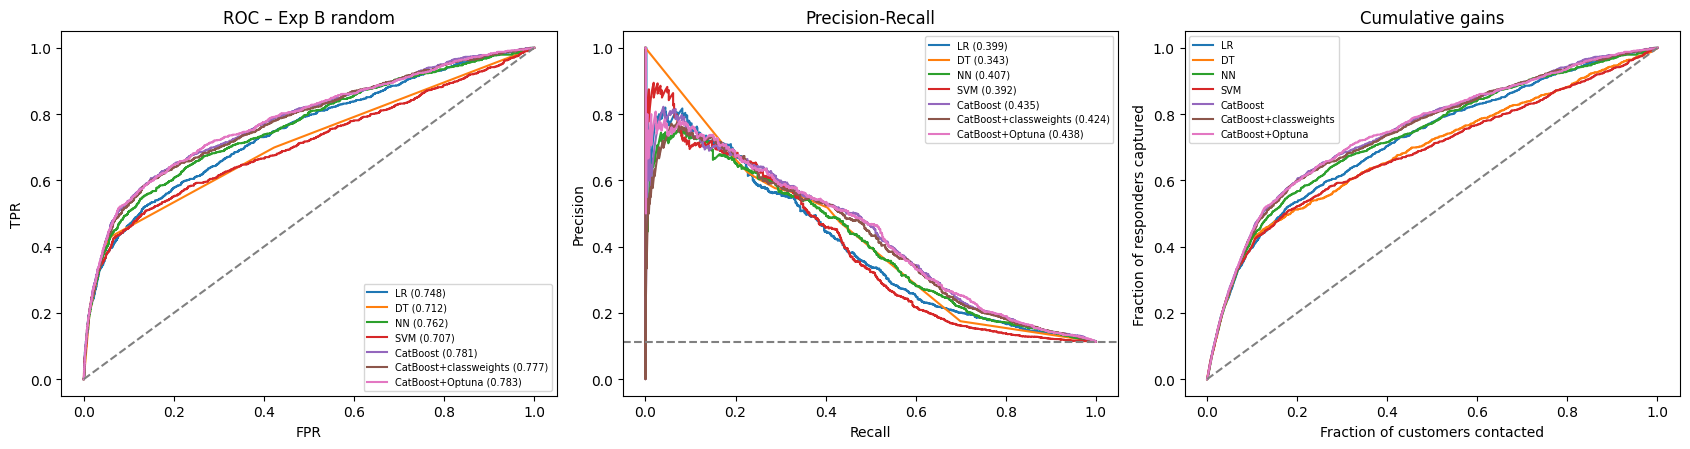

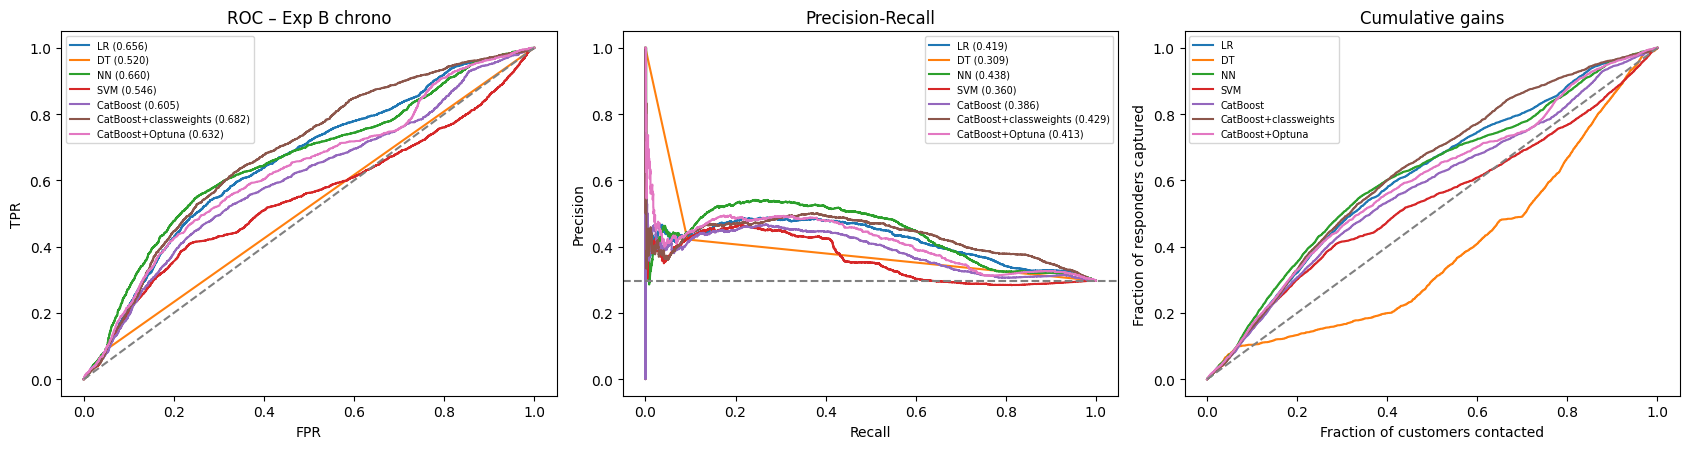

In [18]:
master = pd.concat(RESULTS.values()); master.to_csv(f"{OUT}/master_comparison.csv"); display(master.round(3))
for key in [("B", "random"), ("B", "chrono")]:
    P, models, data = STORE[key]; yte = data[5]; fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    for n, p in P.items():
        f, t, _ = roc_curve(yte, p); ax[0].plot(f, t, label=f"{n} ({roc_auc_score(yte, p):.3f})")
        pr, rc, _ = precision_recall_curve(yte, p); ax[1].plot(rc, pr, label=f"{n} ({average_precision_score(yte, p):.3f})")
        o = np.argsort(-p); ax[2].plot(np.linspace(0, 1, len(yte)+1), np.concatenate([[0], np.cumsum(yte[o])/yte.sum()]), label=n)
    ax[0].plot([0,1],[0,1],"--",c="gray"); ax[2].plot([0,1],[0,1],"--",c="gray"); ax[1].axhline(yte.mean(), ls="--", c="gray")
    ax[0].set(title=f"ROC – Exp {key[0]} {key[1]}", xlabel="FPR", ylabel="TPR"); ax[1].set(title="Precision-Recall", xlabel="Recall", ylabel="Precision")
    ax[2].set(title="Cumulative gains", xlabel="Fraction of customers contacted", ylabel="Fraction of responders captured")
    for a_ in ax: a_.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(f"{OUT}/curves_{key[0]}_{key[1]}.png", dpi=140); plt.show()

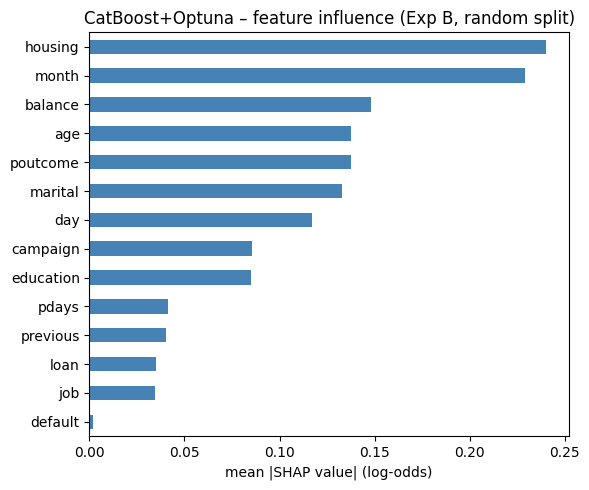

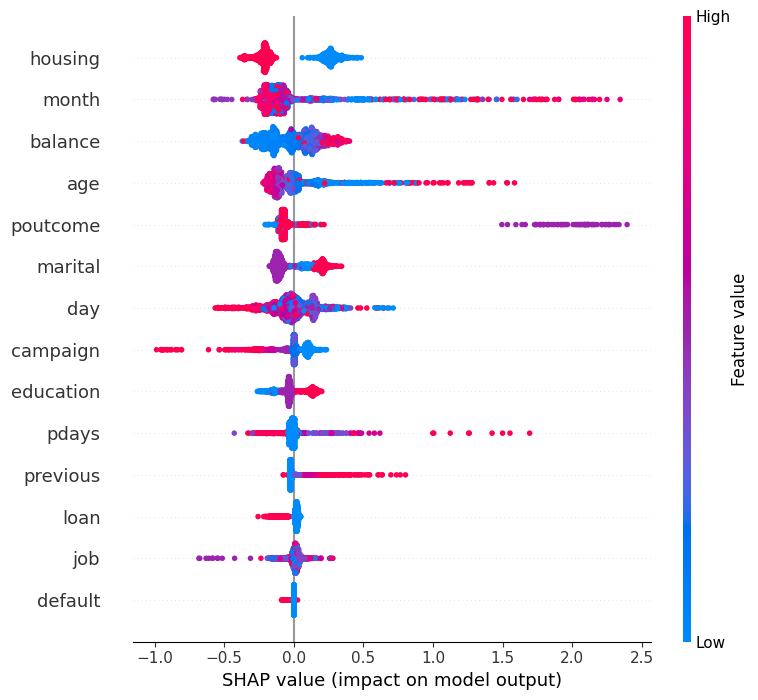

housing      0.240
month        0.229
balance      0.148
age          0.138
poutcome     0.138
marital      0.133
day          0.117
campaign     0.086
education    0.085
pdays        0.042
previous     0.040
loan         0.035
job          0.034
default      0.002


In [19]:
import shap
P, models, data = STORE[("B", "random")]; Xtr, Xva, Xte, ytr, yva, yte, cats = data; cb = models["CatBoost+Optuna"][1]
smp = Xte.sample(min(2000, len(Xte)), random_state=SEED)
sv = cb.get_feature_importance(Pool(smp, cat_features=cats), type="ShapValues")[:, :-1]          # native CatBoost SHAP values
imp = pd.Series(np.abs(sv).mean(0), index=smp.columns).sort_values()
plt.figure(figsize=(6, 5)); imp.plot.barh(color="steelblue"); plt.xlabel("mean |SHAP value| (log-odds)"); plt.title("CatBoost+Optuna – feature influence (Exp B, random split)")
plt.tight_layout(); plt.savefig(f"{OUT}/shap_importance.png", dpi=140); plt.show(); imp.sort_values(ascending=False).to_csv(f"{OUT}/shap_importance.csv")
try:
    shap.summary_plot(sv, smp.assign(**{c: smp[c].astype("category").cat.codes for c in cats}), show=False); plt.savefig(f"{OUT}/shap_beeswarm.png", dpi=140, bbox_inches="tight"); plt.show()
except Exception as e: print("beeswarm skipped:", e)
print(imp.sort_values(ascending=False).round(3).to_string())

In [20]:
for key in [("B", "random"), ("B", "chrono")]:
    r = RESULTS[key][["ROC-AUC", "Top10% captured", "Top20% captured", "Top50% captured", "Lift@10%"]].round(2)
    print(f"\nExperiment {key[0]} – {key[1]} split (random targeting would capture 10/20/50%, lift 1.0):"); display(r)


Experiment B – random split (random targeting would capture 10/20/50%, lift 1.0):


,ROC-AUC,Top10% captured,Top20% captured,Top50% captured,Lift@10%
Model,,,,,
LR,0.75,39.66,53.56,77.59,3.97
DT,0.71,42.35,50.65,72.52,4.23
NN,0.76,42.56,56.79,77.26,4.26
SVM,0.71,40.41,52.16,70.58,4.04
CatBoost,0.78,44.61,60.24,80.60,4.46
CatBoost+classweights,0.78,43.86,59.91,80.06,4.39
CatBoost+Optuna,0.78,44.61,59.70,80.60,4.46



Experiment B – chrono split (random targeting would capture 10/20/50%, lift 1.0):


,ROC-AUC,Top10% captured,Top20% captured,Top50% captured,Lift@10%
Model,,,,,
LR,0.66,15.66,32.14,66.42,1.57
DT,0.52,10.01,12.07,23.07,1.00
NN,0.66,17.55,35.27,66.46,1.76
SVM,0.55,15.25,30.16,55.09,1.52
CatBoost,0.60,15.04,30.78,60.98,1.50
CatBoost+classweights,0.68,15.70,33.17,68.93,1.57
CatBoost+Optuna,0.63,16.56,32.88,63.62,1.66


In [21]:
joblib.dump({"features_B": get_features("B")[0].columns.tolist()}, f"{OUT}/meta.joblib")
STORE[("B", "random")][1]["CatBoost+Optuna"][1].save_model(f"{OUT}/catboost_optuna_expB.cbm")
import shutil; shutil.make_archive("improved_outputs", "zip", OUT)
try:
    from google.colab import files; files.download("improved_outputs.zip")
except ImportError: print("saved improved_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>